# Visualize Cell Crop Images

In [18]:
import pickle
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import numpy as np
sys.path.insert(1, "../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import TIFF_IMGS_DIR
sys.path.insert(1, "../1_snakemake_pipeline/2025_varchamp_snakemake/3.downstream_analyses/scripts/cell_img_visualization")
from scalebar_utils import (
    add_scale_bar,
    calculate_optimal_scale_bar_length,
    add_scale_bar_to_axes_list,
    VARCHAMP_PIXEL_SIZE_UM
)
from cell_selector import (
    filter_cells_by_metadata,
    filter_by_quality_metrics,
    select_phenotype_extreme_cells,
    compute_distance_to_edge,
    select_cells_top_n,
    select_cells_percentile_random
)
from cell_cropper import (
    load_multichannel_cell_crops, 
    extract_cell_crop, 
    get_crop_coordinates_bbox,
    load_cell_image,
    validate_and_pad_crop,
    resize
)
from cell_visualizer import (
    viz_cell_grid, 
    viz_cell_single_channel,
    viz_cell_multi_channel,
    plot_cell_comparison,
)
print(f"VarChAMP Pixel Size: {VARCHAMP_PIXEL_SIZE_UM} µm/pixel")
print(f"\nScale bar calculations:")
print(f"  10 µm bar = {10 / VARCHAMP_PIXEL_SIZE_UM:.2f} pixels")
print(f"  100 µm bar = {100 / VARCHAMP_PIXEL_SIZE_UM:.2f} pixels")

VarChAMP Pixel Size: 0.598 µm/pixel

Scale bar calculations:
  10 µm bar = 16.72 pixels
  100 µm bar = 167.22 pixels


## 1. Loading data

In [2]:
profiles = pl.scan_parquet(
    "/home/shenrunx/igvf/varchamp/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/batch_prof_filtered_metadata.parquet"
).collect()

# Add distance to edge column (required for quality filtering)
profiles = profiles.with_columns(compute_distance_to_edge().alias("dist2edge"))

# profile_feats = pl.scan_parquet(
#     "/home/shenrunx/igvf/varchamp/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_var_mad_all_feats_filtered_cells.parquet"
# ).unique(subset=["Metadata_CellID"], keep="first").collect()
# profiles = profiles.join(
#     profile_feats.select(["Metadata_CellID"]+[
#         c for c in profile_feats.columns if c not in profiles.columns
#     ]),
#     on="Metadata_CellID"
# )

In [104]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/0_imaging_phenotype_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_pheno_hits = imaging_summary_clinvar.filter(
    pl.col("img_pheno_hit"),
)
imaging_summary_clinvar_misloc_hits = imaging_summary_clinvar.filter(
    pl.col("img_misloc_hit"),
)

cluster_analysis_df = pl.read_csv("../../3_outputs/3_img_pheno_var_clustering_analysis_results.csv")
cluster_results_df = pl.read_csv("../../3_outputs/3_img_pheno_var_clustering_results.csv").join(
    cluster_analysis_df,
    left_on="Metadata_gene_allele",
    right_on="gene_allele"
)

## 2. Single gene

In [16]:
def plot_multi_cell_plots(batch_allele_cells, feat="Cells_AreaShape_Area", crop_size=128, n_cells=5, seed=42, channels=["GFP"]):
    plt.clf()
    fig, axes = plt.subplots(n_cells, len(batch_allele_cells.items()), figsize=(len(batch_allele_cells.items())*3, n_cells*3))
    for idx, allele_cells in enumerate(batch_allele_cells.items()):
        allele_cell_profiles = select_cells_percentile_random(
            batch_allele_cells[allele_cells[0]],
            feature=feat,
            percentile_bins=[(25, 75)],
            n_per_bin=1000,
            seed=seed
        )#.sort("Abs_dev", descending=True)
        # print(len(allele_cell_profiles))
        cell_idx = 0
        for j in range(n_cells):
            # Keep loading cells until we find one with std >= 50
            var_crops = load_multichannel_cell_crops(
                allele_cell_profiles[cell_idx],
                channels,
                imgs_dir=TIFF_IMGS_DIR,
                method='fixed',
                crop_size=crop_size,
            )
            # print(var_crops)
            # Skip cells with low std (likely background/empty)
            while np.std(var_crops["GFP"]) < 50:
                cell_idx += 1  # Move to next cell FIRST
                if cell_idx >= len(allele_cell_profiles):
                    print(f"Warning: Ran out of cells for {allele_cells[0]}")
                    break
                var_crops = load_multichannel_cell_crops(
                    allele_cell_profiles[cell_idx],
                    channels,
                    imgs_dir=TIFF_IMGS_DIR,
                    method='fixed',
                    crop_size=crop_size,
                )

            viz_cell_single_channel(
                var_crops[channels[0]],
                channel=channels[0],
                ax=axes[j, idx],
                axis_off=True,
                percentile_low=1,
                percentile_high=99,
                # title=f'A{idx+1}' if j % 5 == 0 else None
            )
            cell_idx += 1  # Move to next cell for the next iteration of j

        axes[0, idx].set_title(allele_cells[0], fontsize=18)
        # Add 10 µm scale bar post-hoc
        add_scale_bar(
            axes[0, idx],
            pixel_size_um=VARCHAMP_PIXEL_SIZE_UM,
            image_width_pixels=256,
            scale_bar_length_um=20,
            location='lower right',
            color='white',
            fontsize=10
        )
        # axes[0, idx].text(-0.15, 0.5, allele_cells[0],
        #                 transform=axes[0, idx].transAxes,
        #                 fontsize=14, fontweight='bold',
        #                 rotation=90, va='center', ha='right')

    plt.tight_layout()
    plt.subplots_adjust(wspace=0)
    plt.show()

### 2.1 GFAP

In [33]:
# Load cell crops for one cell
def plot_single_cell_crop(allele, cell_crops, channels, idx=0, ax=None):
    # channels = ['GFP']
    cell_crop = load_multichannel_cell_crops(
        cell_crops[idx],
        channels,
        imgs_dir=TIFF_IMGS_DIR,
        method='fixed',
        crop_size=256
    )

    # Create figure and display image using existing function
    if ax is None:
        fig, ax = plt.subplots(figsize=(3, 3))
    
    if len(channels)== 1:
        viz_cell_single_channel(
            cell_crop[channels[0]],
            channel=channels[0],
            ax=ax,
            axis_off=True,
            percentile_low=1.0,
            percentile_high=99.0,
            title=""
        )
    else:
        viz_cell_multi_channel(
            cell_crop,
            channels=channels,
            channel_mapping='gfp_inclusive',
            contrast_percentiles=95,
            ax=ax,
            axis_off=True,
            title=""
        )

    ax.set_title(allele, fontsize=15)
    # Add 10 µm scale bar post-hoc
    add_scale_bar(
        ax,
        pixel_size_um=VARCHAMP_PIXEL_SIZE_UM,
        image_width_pixels=256,
        scale_bar_length_um=20,
        location='lower right',
        color='white',
        fontsize=10
    )

    if ax == None:
        plt.show()

In [34]:
gfap_alleles_df = imaging_summary_clinvar_pheno_hits.filter(
    pl.col("gene_variant").str.contains("GFAP")
)
gfap_alleles = ["GFAP"]+sorted(gfap_alleles_df["gene_variant"].to_list(), key=lambda x: int(x[8:-3]))
gfap_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=50
    )
     for allele in gfap_alleles
}

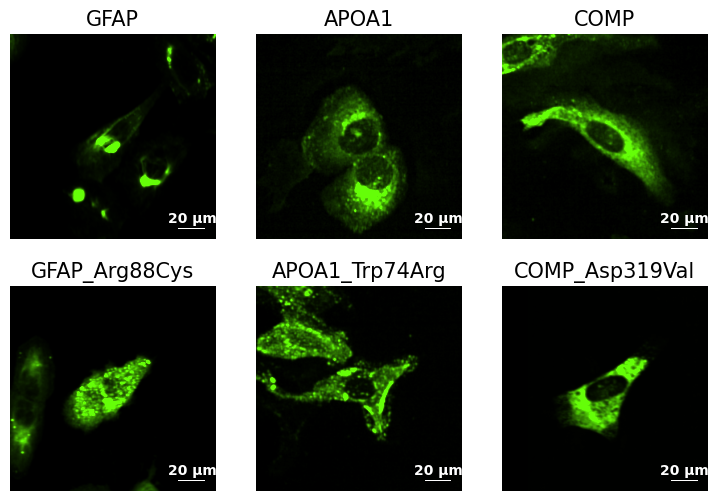

In [48]:
fig, axes = plt.subplots(2,3,figsize=(9,6))
plot_single_cell_crop("GFAP_Arg88Cys", gfap_allele_cells["GFAP_Arg88Cys"], channels=["GFP"], idx=10, ax=axes[1,0])
plot_single_cell_crop("GFAP", gfap_allele_cells["GFAP"], channels=["GFP"], idx=4, ax=axes[0,0])

plot_single_cell_crop(
    "APOA1_Trp74Arg", 
    filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele="APOA1_Trp74Arg"),
        min_edge_dist=50
    ), 
    channels=["GFP"],
    idx=3, ax=axes[1,1]
)
plot_single_cell_crop(
    "APOA1", 
    filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele="APOA1"),
        min_edge_dist=50
    ), 
    channels=["GFP"],
    idx=2, ax=axes[0,1]
)
plot_single_cell_crop(
    "COMP", 
    filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele="COMP"),
        min_edge_dist=50
    ), 
    channels=["GFP"],
    idx=2, ax=axes[0,2]
)
plot_single_cell_crop(
    "COMP_Asp319Val", 
    filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele="COMP_Asp319Val"),
        min_edge_dist=50
    ), 
    channels=["GFP"],
    idx=5, ax=axes[1,2]
)
plt.show()

In [25]:
# feats_to_plot = ["Cytoplasm_Texture_Entropy_GFP_10_00_256", "Cytoplasm_Correlation_Correlation_AGP_GFP"]
# df_temp = profiles.filter(
#     pl.col("Metadata_gene_allele").is_in(gfap_alleles),
# )

# fig, axes = plt.subplots(2,1,figsize=(10,7),sharex=True)
# for i, feat in enumerate(feats_to_plot):
#     sns.violinplot(
#         data=df_temp.to_pandas(),
#         x="Metadata_gene_allele",
#         y=feat,
#         order=gfap_alleles,
#         ax=axes[i]
#     )
#     axes[i].set_ylabel(f"{feat.split('_')[0]}\n{'_'.join(feat.split('_')[1:3])}\n{'_'.join(feat.split('_')[3:])}\n(A.U.)", fontsize=8)
#     ref_median = df_temp.filter(pl.col("Metadata_gene_allele")=="GFAP")[feat].median()
#     axes[i].axhline(ref_median, color='darkblue', linestyle='--', linewidth=1.5)
#     axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=8)

# axes[-1].set_xlabel("GFAP Phenotype Variants", fontsize=8)
# axes[-1].set_xticklabels([x.get_text().split('_')[-1] for x in axes[-1].get_xticklabels()], fontsize=8, rotation=25, ha='right')
# plt.subplots_adjust(hspace=0.12)
# plt.show()

In [64]:
with pl.Config(set_tbl_rows=20):
    print(gfap_alleles_df["gene_variant", "img_pheno_score","clinvar_clnsig_clean_pp_strict"].sort("img_pheno_score", descending=True))#.to_list()
    print(
        imaging_summary_clinvar.filter(
            pl.col("Gene")=="GFAP",
            ~pl.col("gene_variant").is_in(gfap_alleles_df["gene_variant"])
        )["gene_variant", "img_pheno_score", "clinvar_clnsig_clean_pp_strict"].sort("img_pheno_score", descending=True)
    )

shape: (13, 3)
┌────────────────┬─────────────────┬────────────────────────────────┐
│ gene_variant   ┆ img_pheno_score ┆ clinvar_clnsig_clean_pp_strict │
│ ---            ┆ ---             ┆ ---                            │
│ str            ┆ f64             ┆ str                            │
╞════════════════╪═════════════════╪════════════════════════════════╡
│ GFAP_Arg88Cys  ┆ 0.977091        ┆ Pathogenic                     │
│ GFAP_Arg79Ser  ┆ 0.973553        ┆ VUS                            │
│ GFAP_Lys236Thr ┆ 0.973388        ┆ Others                         │
│ GFAP_Asn77Ser  ┆ 0.968469        ┆ Pathogenic                     │
│ GFAP_Leu352Pro ┆ 0.967293        ┆ Pathogenic                     │
│ GFAP_Leu90Pro  ┆ 0.962373        ┆ Others                         │
│ GFAP_Glu371Gly ┆ 0.958287        ┆ Others                         │
│ GFAP_Leu235Pro ┆ 0.958086        ┆ Others                         │
│ GFAP_Arg79Cys  ┆ 0.955883        ┆ Pathogenic                     │
│ GFA

In [66]:
# def plot_single_allele(allele_cell_profiles, num_r, num_col, channels=["GFP"]):
#     fig, axes = plt.subplots(num_r, num_col, figsize=(num_r*3, num_col*3))
#     cell_idx = 0
#     for idx in range(num_r*num_col):
#         # Keep loading cells until we find one with std >= 50
#         var_crops = load_multichannel_cell_crops(
#             allele_cell_profiles[cell_idx],
#             channels,
#             imgs_dir=TIFF_IMGS_DIR,
#             method='fixed',
#             crop_size=256,
#         )
#         # Skip cells with low std (likely background/empty)
#         while np.std(var_crops["GFP"]) < 1000:
#             cell_idx += 1  # Move to next cell FIRST
#             if cell_idx >= len(allele_cell_profiles):
#                 print(f"Warning: Ran out of cells")
#                 break
#             var_crops = load_multichannel_cell_crops(
#                 allele_cell_profiles[cell_idx],
#                 channels,
#                 imgs_dir=TIFF_IMGS_DIR,
#                 method='fixed',
#                 crop_size=256,
#             )
#         viz_cell_single_channel(
#             var_crops[channels[0]],
#             channel=channels[0],
#             ax=axes[idx//num_col, idx%num_col],
#             axis_off=True,
#             percentile_low=2.5,
#             percentile_high=97.5,
#             # title=f'A{idx+1}' if j % 5 == 0 else None
#         )
#         cell_idx += 1  # Move to next cell for the next iteration of j
#     plt.tight_layout()
#     plt.subplots_adjust(wspace=0.1, hspace=-.94)
#     plt.show()

# plot_single_allele(
#     select_cells_percentile_random(
#         gfap_allele_cells["GFAP"],
#         feature="Cytoplasm_Texture_Entropy_GFP_10_00_256",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=1000,
#         seed=0
#     ),#.sort("Abs_dev", descending=True),
#     num_r=5, num_col=10
# )

# plot_single_allele(
#     select_cells_percentile_random(
#         gfap_allele_cells["GFAP_Arg88Cys"],
#         feature="Cytoplasm_Texture_Entropy_GFP_10_00_256",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=1000,
#         seed=0
#     ),#.sort("Abs_dev", descending=True),
#     num_r=5, num_col=10
# )

# plot_single_allele(
#     select_cells_percentile_random(
#         gfap_allele_cells["GFAP_Leu235Pro"],
#         feature="Cytoplasm_Correlation_Correlation_AGP_GFP",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=1000,
#         seed=4
#     ),#.sort("Abs_dev", descending=True),
#     num_r=5, num_col=10
# )

In [51]:
# Create figure: 2 rows (VAR on top, REF on bottom) x 20 columns (one per cell)
# plot_multi_cell_plots(gfap_allele_cells)

### 2.2 MLH1

In [101]:
# allele_cell_profiles = select_cells_percentile_random(
#     mlh1_allele_cells["MLH1_Leu653Pro"],
#     feature="Cells_AreaShape_Area",
#     percentile_bins=[(40, 60)],  # Top 20% of feature values
#     n_per_bin=1000,
#     seed=42
# )

# fig, axes = plt.subplots(1, 5)
# # print(len(allele_cell_profiles))
# cell_idx = 0
# # print(len(allele_cell_profiles))
# for j in range(5):
#     # Keep loading cells until we find one with std >= 50
#     var_crops = load_multichannel_cell_crops(
#         allele_cell_profiles[cell_idx],
#         channels,
#         imgs_dir=TIFF_IMGS_DIR,
#         method='fixed',
#         crop_size=128,
#     )
#     # print(var_crops)
#     # Skip cells with low std (likely background/empty)
#     while np.std(var_crops["GFP"]) < 50:
#         cell_idx += 1  # Move to next cell FIRST
#         if cell_idx >= len(allele_cell_profiles):
#             print(f"Warning: Ran out of cells for {allele_cells[0]}")
#             break
#         var_crops = load_multichannel_cell_crops(
#             allele_cell_profiles[cell_idx],
#             channels,
#             imgs_dir=TIFF_IMGS_DIR,
#             method='fixed',
#             crop_size=128,
#         )
#     viz_cell_single_channel(
#         var_crops[channels[0]],
#         channel=channels[0],
#         ax=axes[j],
#         axis_off=True,
#         percentile_low=1.0,
#         percentile_high=99.0,
#         # title=f'A{idx+1}' if j % 5 == 0 else None
#     )
#     cell_idx += 1  # Move to next cell FIRST
# plt.show()

In [105]:
mlh1_allele_cluster_df = cluster_results_df.with_columns(
    pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
).filter(
    pl.col("Gene")=="MLH1"
).sort("Metadata_img_pheno_score", descending=True).select(
    "Metadata_gene_allele","Metadata_img_pheno_score", "Metadata_cluster"
).unique("Metadata_cluster")
mlh1_allele_cluster_df

Metadata_gene_allele,Metadata_img_pheno_score,Metadata_cluster
str,f64,i64
"""MLH1_Lys670Arg""",0.943246,1
"""MLH1_Ser295Thr""",0.978243,9
"""MLH1_Leu653Pro""",0.982095,7
"""MLH1_Ser44Phe""",0.997603,6


In [1]:
# mlh1_allele_cluster_df = cluster_result_df.with_columns(
#     pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
# ).filter(
#     pl.col("Gene")=="MLH1"
# ).sort("Metadata_img_pheno_score", descending=True).select(
#     "Metadata_gene_allele","Metadata_img_pheno_score", "Metadata_cluster"
# ).unique("Metadata_cluster")["Metadata_gene_allele"].to_list()
# # mlh1_alleles = mlh1_allele_cluster_df["gene_allele"].to_list()
# display(mlh1_allele_cluster_df)

# mlh1_allele_group1_cells = {
#     allele: filter_by_quality_metrics(
#         filter_cells_by_metadata(profiles, allele=allele),
#         min_edge_dist=50
#     )
#     for allele in ["MLH1"]+['MLH1_Val185Gly','MLH1_Lys670Arg','MLH1_Ser44Phe']
# }

# mlh1_allele_group2_cells = {
#     allele: filter_by_quality_metrics(
#         filter_cells_by_metadata(profiles, allele=allele),
#         min_edge_dist=50
#     )
#     for allele in ["MLH1"]+['MLH1_Leu653Pro','MLH1_Ser295Thr']
# }

# plot_multi_cell_plots(mlh1_allele_group1_cells, feat="Cells_Correlation_Correlation_DNA_GFP", crop_size=256, n_cells=5, seed=10)

In [2]:
# plot_multi_cell_plots(mlh1_allele_group2_cells, feat="Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256", crop_size=256, n_cells=5, seed=42)

### 2.3 LITAF

In [52]:
imaging_summary_clinvar_pheno_hits.filter(
    pl.col("Gene")=="LITAF"
).sort(
    "img_pheno_score", descending=True
).select(
    "gene_variant", "img_pheno_score"
)

gene_variant,img_pheno_score
str,f64
"""LITAF_Pro84Leu""",0.978472
"""LITAF_Ser118Pro""",0.978325
"""LITAF_Trp116Gly""",0.977486
"""LITAF_Val144Met""",0.977335
"""LITAF_Leu122Val""",0.975058
"""LITAF_Pro135Arg""",0.97147
"""LITAF_Phe136Leu""",0.963864
"""LITAF_Pro135Ser""",0.962524
"""LITAF_Pro135Thr""",0.960699


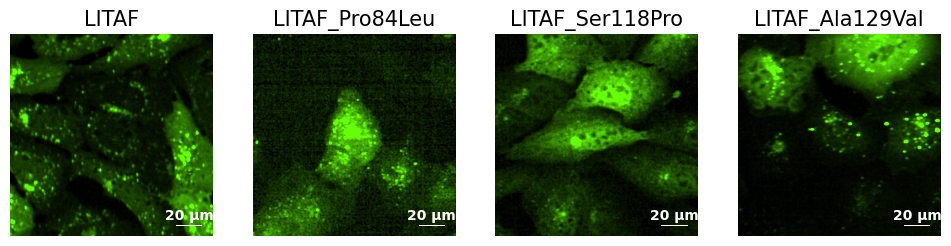

In [99]:
litaf1_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=50
    )
    for allele in ["LITAF"]+["LITAF_Pro84Leu", "LITAF_Ser118Pro", "LITAF_Ala129Val"]
}

fig, axes = plt.subplots(1,4,figsize=(12,3))
plot_single_cell_crop("LITAF", litaf1_allele_cells["LITAF"], channels=["GFP"], idx=4, ax=axes[0])
plot_single_cell_crop("LITAF_Pro84Leu", litaf1_allele_cells["LITAF_Pro84Leu"], channels=["GFP"], idx=110, ax=axes[1])
plot_single_cell_crop("LITAF_Ser118Pro", litaf1_allele_cells["LITAF_Ser118Pro"], channels=["GFP"], idx=10, ax=axes[2])
plot_single_cell_crop("LITAF_Ala129Val", litaf1_allele_cells["LITAF_Ala129Val"], channels=["GFP"], idx=80, ax=axes[3])
plt.show()

In [80]:
with pl.Config(set_tbl_rows=1000):
    imaging_summary_clinvar.filter(
        pl.col("gene_variant").str.contains("LITAF")
    ).select("gene_variant","img_pheno_score","img_pheno_hit")

### 2.4 PLP1

https://www.perplexity.ai/search/collect-all-available-clinical-v.imj0YTT3mMX2QIbC_I2w#0

In [ ]:
with pl.Config(set_tbl_rows=1000):
    display(
        imaging_summary_clinvar_pheno_hits.filter(
            pl.col("gene_variant").str.contains("PLP1")
        ).select("gene_variant","img_pheno_score","img_pheno_hit").sort(
            "img_pheno_score", descending=True
        ).select("gene_variant")
    )

gene_variant
str
"""PLP1_Gly74Arg"""
"""PLP1_Thr147Pro"""
"""PLP1_Cys193Tyr"""
"""PLP1_Thr43Ile"""
"""PLP1_Leu189Pro"""
"""PLP1_Trp128Arg"""
"""PLP1_Ile152Thr"""
"""PLP1_Gly186Cys"""
"""PLP1_Asp168His"""


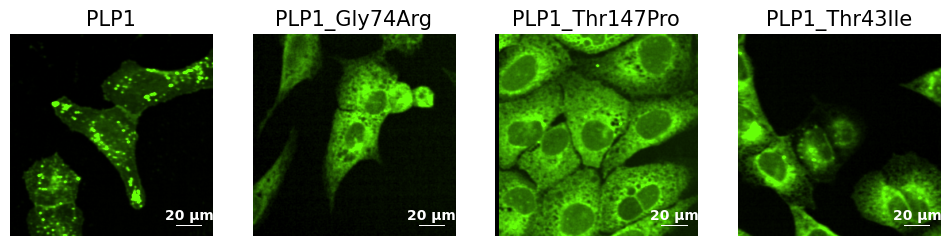

In [127]:
plp1_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=50
    )
    for allele in ["PLP1"]+["PLP1_Gly74Arg", "PLP1_Thr147Pro", "PLP1_Thr43Ile"]
}

fig, axes = plt.subplots(1,4,figsize=(12,3))
plot_single_cell_crop("PLP1", plp1_allele_cells["PLP1"], channels=["GFP"], idx=6, ax=axes[0])
plot_single_cell_crop("PLP1_Gly74Arg", plp1_allele_cells["PLP1_Gly74Arg"], channels=["GFP"], idx=50, ax=axes[1])
plot_single_cell_crop("PLP1_Thr147Pro", plp1_allele_cells["PLP1_Thr147Pro"], channels=["GFP"], idx=10, ax=axes[2])
plot_single_cell_crop("PLP1_Thr43Ile", plp1_allele_cells["PLP1_Thr43Ile"], channels=["GFP"], idx=80, ax=axes[3])
plt.show()

## 3. Cluster Analyses

In [40]:
cluster_alleles = cluster_analysis_df.filter(
    pl.col("cluster")==4
)["gene_allele"].to_list()

cluster_alleles_keys = cluster_result_df.filter(
    pl.col("Metadata_cluster")==4
).sort("Metadata_img_pheno_score", descending=True).select(
    "Metadata_gene_allele","Metadata_img_pheno_score"
).with_columns(
    pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
).unique("Gene")["Metadata_gene_allele"].to_list()


cluster1_alleles = sorted(set([al.split('_')[0] for al in cluster_alleles_keys]+cluster_alleles_keys))
batch_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=200
    )
     for allele in cluster1_alleles[:10]+["PLP1_Trp128Arg"]
}

In [4]:
# plot_multi_cell_plots(batch_allele_cells, feat="Cells_Correlation_Correlation_GFP_Mito", crop_size=256, n_cells=5, seed=10)

In [34]:
# # Create figure: 2 rows (VAR on top, REF on bottom) x 20 columns (one per cell)
# n_cells = 5
# fig, axes = plt.subplots(len(batch_allele_cells.items()), n_cells, figsize=(n_cells*3, len(batch_allele_cells.items())*3))
# channels = ["GFP"]

# for idx, allele_cells in enumerate(batch_allele_cells.items()):
#     print(allele_cells[0])
#     allele_cell_profiles = select_cells_percentile_random(
#         batch_allele_cells[allele_cells[0]],
#         feature="Cells_AreaShape_Area",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=n_cells*5,
#         seed=42
#     )
#     cell_idx = 0
#     for j in range(n_cells):
#         # Keep loading cells until we find one with std >= 50
#         var_crops = load_multichannel_cell_crops(
#             allele_cell_profiles[cell_idx],
#             channels,
#             imgs_dir=TIFF_IMGS_DIR,
#             method='fixed',
#             crop_size=128,
#         )
#         # Skip cells with low std (likely background/empty)
#         while np.std(var_crops["GFP"]) < 100:
#             cell_idx += 1  # Move to next cell FIRST
#             if cell_idx >= len(allele_cell_profiles):
#                 print(f"Warning: Ran out of cells for {allele_cells[0]}")
#                 break
#             var_crops = load_multichannel_cell_crops(
#                 allele_cell_profiles[cell_idx],
#                 channels,
#                 imgs_dir=TIFF_IMGS_DIR,
#                 method='fixed',
#                 crop_size=128,
#             )
#         viz_cell_single_channel(
#             var_crops['GFP'],
#             channel='GFP',
#             ax=axes[idx, j],
#             axis_off=True,
#             percentile_low=1.0,
#             percentile_high=99.0,
#             title=f'A{j+1}' if j % 5 == 0 else None
#         )
#         cell_idx += 1  # Move to next cell for the next iteration of j

#     axes[idx, 0].text(-0.15, 0.5, allele_cells[0],
#                     transform=axes[idx, 0].transAxes,
#                     fontsize=14, fontweight='bold',
#                     rotation=90, va='center', ha='right')

# plt.tight_layout()
# plt.subplots_adjust(wspace=0)
# plt.show()